# 第8章 制储用氢系统协同运行

本Notebook已执行，采用作者构造数据。五组可运行单元依次完成手算、三策略求解、独立账本、可视化与备用量实验。全部计算在CPU完成；交互课堂页面见demo/ch08/教学演示.html。

## 1 5 kg/h需要多少电功率

电解、压缩、辅助分别计入。质量库存与压力换算采用明确单位。

In [1]:
from pathlib import Path
import sys, json, io
from dataclasses import replace
import numpy as np
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch08/model.py").exists())
sys.path.insert(0, str(root / "chapters/ch08"))
from model import config, profiles, step, plan, simulate, summary, pressure
c = config(80)
r = step(275, 50, 0, 100, 5, 650, c)
print("电解/压缩/辅助/总输入 (kW):", r["p"], r["compressor"], r["auxiliary"], r["total"])
print("区间产氢 (kg):", r["q"] * c.dt)
print("50 kg / 25℃ / Z=1 压力 (bar):", float(pressure(50, c)))
assert abs(r["total"] - 295) < 1e-9
assert abs(r["m_after"] - 50) < 1e-9

电解/压缩/辅助/总输入 (kW): 275.0 15.0 5.0 295.0
区间产氢 (kg): 1.25
50 kg / 25℃ / Z=1 压力 (bar): 122.95705999999998


## 2 从头求解三种策略

基准输入固定，日前硬终端与滚动软终端条件公开；记录购电、缺供和期末库存。

In [2]:
nominal = profiles()
commands, solver = plan(nominal, c)
traces = {}
for policy in ["on_demand", "day_ahead", "rolling"]:
    rows, solves = simulate(policy, nominal, c, commands=commands)
    traces[policy] = rows
    metrics = summary(rows, c)
    print(policy, {k: round(metrics[k], 3) for k in ["electricity_cost", "shortage_kg", "end_kg"]})
    assert metrics["shortage_kg"] < 1e-6
print("日前求解状态 / 最优间隙:", solver["status"], solver["gap"])

on_demand {'electricity_cost': np.float64(4965.72), 'shortage_kg': np.float64(0.0), 'end_kg': np.float64(50.0)}
day_ahead {'electricity_cost': np.float64(2802.728), 'shortage_kg': np.float64(0.0), 'end_kg': np.float64(50.0)}
rolling {'electricity_cost': np.float64(3506.091), 'shortage_kg': np.float64(0.0), 'end_kg': np.float64(50.0)}
日前求解状态 / 最优间隙: 0 0.0


## 3 独立重算总账

从原始执行记录求和，检查质量和电能守恒。

In [3]:
for policy, rows in traces.items():
    mass = rows[-1]["m_after"] - c.m0 - sum((r["q"] - r["served"]) * c.dt - r["loss"] for r in rows)
    energy = sum((r["grid"] + r["renewable"] - r["curtailment"] - r["p"] - r["compressor"] - r["auxiliary"]) * c.dt for r in rows)
    print(policy, "质量残差/kg:", mass, "电能残差/kWh:", energy)
    assert abs(mass) < 1e-6 and abs(energy) < 1e-6
empty = step(0, c.mmin, 0, 0, 8, 0, c)
print("零可用库存时缺供 (kg/h):", empty["shortage"])
assert empty["shortage"] == 8

on_demand 质量残差/kg: -4.440892098500626e-15 电能残差/kWh: -1.4921397450962104e-13
day_ahead 质量残差/kg: -6.017408793468348e-14 电能残差/kWh: 2.5979218776228663e-14
rolling 质量残差/kg: 3.730349362740526e-14 电能残差/kWh: 6.750155989720952e-14
零可用库存时缺供 (kg/h): 8


## 4 绘制刚刚求解的轨迹

颜色跨图保持一致，轴标给出物理单位。

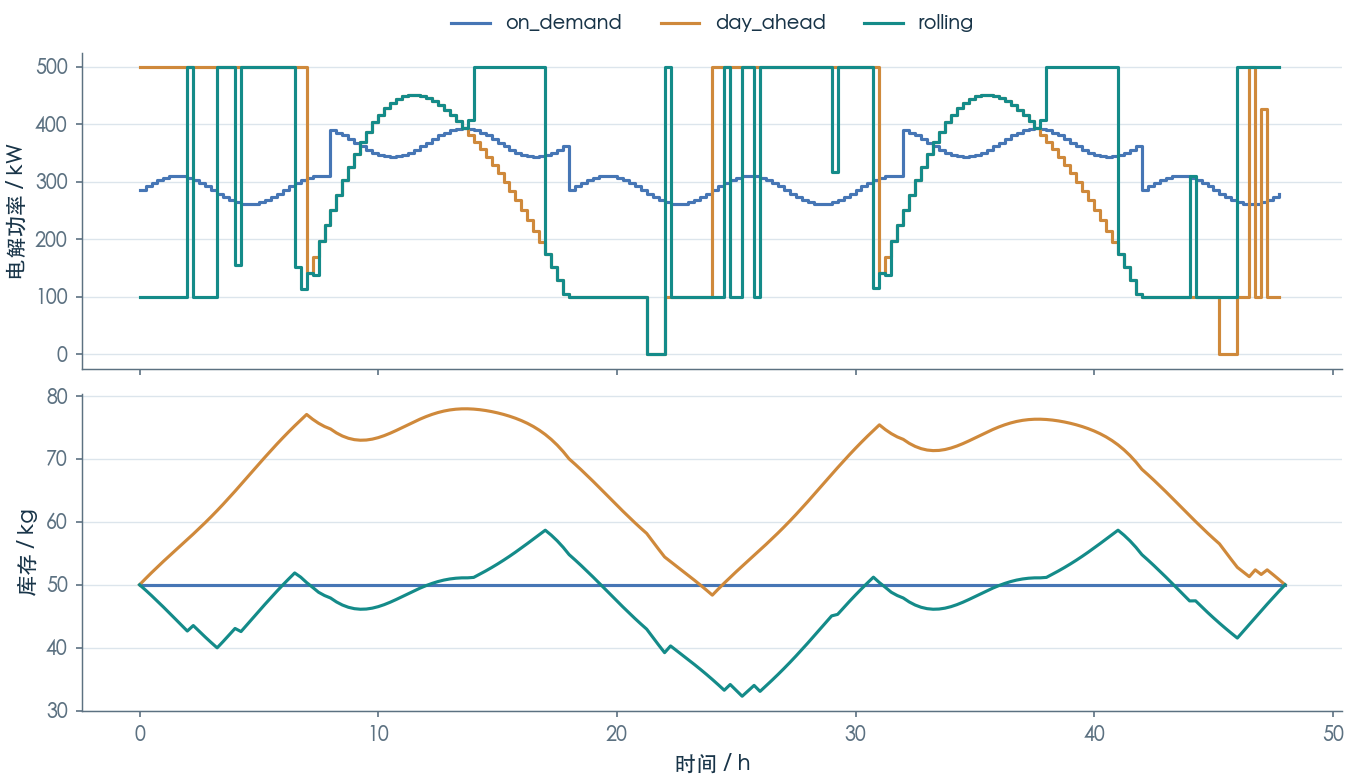

In [4]:
from visual_style import setup, plt, style
from IPython.display import Image, display
setup()
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, layout="constrained")
for (name, rows), col in zip(traces.items(), ["#4676b5", "#cf893b", "#148b89"]):
    t = [r["time"] for r in rows]
    axes[0].step(t, [r["p"] for r in rows], where="post", color=col, label=name)
    axes[1].plot(np.r_[t, 48], np.r_[50, [r["m_after"] for r in rows]], color=col)
axes[0].set_ylabel("电解功率 / kW")
axes[0].legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(.5, 1.01))
axes[1].set(xlabel="时间 / h", ylabel="库存 / kg")
for ax in axes: style(ax)
buffer = io.BytesIO(); fig.savefig(buffer, format="png", dpi=150); plt.close(fig)
display(Image(data=buffer.getvalue()))

## 5 固定容量，改变初始备用量

区别于主实验同步改变容量与初值，这里保持80 kg上限与5 m³容积，单独扫描初始库存。

In [5]:
for initial in [30., 50., 70.]:
    cfg = replace(c, m0=initial)
    rows, _ = simulate("on_demand", profiles("supply_cap"), cfg)
    metrics = summary(rows, cfg)
    print(f"initial={initial:.0f} kg | shortage={metrics['shortage_kg']:.3f} kg | end={metrics['end_kg']:.3f} kg | electricity={metrics['electricity_cost']:.2f} RMB")
print("练习：固定50 kg初值，扫描60/80/120 kg上限，比较两类实验回答的问题。")

initial=30 kg | shortage=48.979 kg | end=29.926 kg | electricity=5257.33 RMB
initial=50 kg | shortage=28.979 kg | end=48.145 kg | electricity=6273.59 RMB
initial=70 kg | shortage=8.979 kg | end=53.501 kg | electricity=6485.47 RMB
练习：固定50 kg初值，扫描60/80/120 kg上限，比较两类实验回答的问题。


## 后续扩展

在共同执行器下增加备用约束或预测模型，记录全部实验条件、求解状态、缺供和期末库存。压力物性、组件动态与λ>0库存损失需要进一步验证。完整运行与52540项检查命令见README。